# Lab 15 — Flying a VLA safely

**Book sections:** [12.4](../../book/docs/chapters/12-embodied/interfaces.md),
[13.3](../../book/docs/chapters/13-uavs/architectures.md)–[13.5](../../book/docs/chapters/13-uavs/safety.md).

**Goal.** Put the toy VLA of Lab 11 on a "drone" over the depot and study the architecture and safety questions
of Chapter 13 with measurements instead of arguments:

1. **direct action** (architecture D): the VLA's velocity actions are streamed to the vehicle;
2. **goal level** (architecture B): the VLA's predicted chunk is turned into a waypoint, and a classical
   controller flies to it at the control rate;
3. a **safety envelope**: keep-out zones the policy cannot see, a control-barrier-function filter with margins,
   and a watchdog — under latency, wind and link loss.

The drone (`vlacourse.drone_depot.DroneDepot`) tracks velocity setpoints with a 0.25 s lag under wind gusts;
physics at 50 Hz, decisions at 10 Hz. Everything is 2-D and simulated; the lessons are about structure.

**Runtime:** ≈8 min with a GPU. **Downloads:** none. **GPU:** < 1 GB. **Seed:** 0.
**Reads** `data/checkpoints/toy_vla_mse.pt` (Lab 11) and `tiny_clip.pt` (Lab 07).

In [1]:
import collections
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from vlacourse.clip import TinyCLIP
from vlacourse.data import scenes
from vlacourse.depot_env import INSTR_VOCAB, encode_instruction, pad_instructions
from vlacourse.drone_depot import DroneDepot
from vlacourse.safety import cbf_filter
from vlacourse.seed import device, set_seed
from vlacourse.vision import to_tensor
from vlacourse.vla import TinyVLA

set_seed(0)
dev = device()
CK = Path("../../data/checkpoints")

clip = TinyCLIP(len(scenes.VOCAB))
clip.load_state_dict(torch.load(CK / "tiny_clip.pt", map_location="cpu"))
vla = TinyVLA(len(INSTR_VOCAB), head="mse", vision=clip.image_encoder).to(dev)
vla.load_state_dict(torch.load(CK / "toy_vla_mse.pt", map_location=dev))
vla.eval()
print("loaded the Lab 11 policy (regression head, 8-action chunks)")

loaded the Lab 11 policy (regression head, 8-action chunks)


## 1. The flight loop
One function flies `n` episodes in lockstep. Options:

* `mode="direct"`: query the VLA when the action queue is empty and stream 4 actions from each chunk
  (as in Lab 11);
* `mode="goal"`: query the VLA every 5 steps (2 Hz); the waypoint is the observed position plus the chunk's
  total displacement, $\mathbf{g}=\mathbf{p}_\text{obs}+v\sum_h\mathbf{a}_h$; a proportional controller flies to it
  every step with the *current* position;
* `latency`: the VLA sees the observation from `latency` control steps (×100 ms) ago;
* `outage`: (start step, length) during which no VLA decision is delivered (link loss);
* `filt`: a CBF filter on every command, with zone `margin` and rate `alpha` (book 12.4);
* `watchdog`: if no decision was delivered for `wd_steps`, command zero velocity (hover);
* `hold`: success requires staying within the target radius for `hold` control steps (0.5 s by default) —
  "hover over the red toolbox", not just "fly through it".

In [2]:
V_STEP = DroneDepot().v_step


@torch.no_grad()
def query(images, instr, states):
    return vla.act(to_tensor(np.stack(images)).to(dev), torch.as_tensor(np.stack(instr)).to(dev),
                   torch.as_tensor(np.stack(states)).to(dev)).cpu().numpy()


def fly(n=200, mode="direct", latency=0, zone_prob=0.0, filt=False, margin=0.03, alpha=3.0, watchdog=False,
        wd_steps=3, outage=None, seed=30_000, trace=False, hold=5):
    envs = [DroneDepot(zone_prob=zone_prob, hold_steps=hold) for _ in range(n)]
    obs = [e.reset(seed + i) for i, e in enumerate(envs)]
    ins = pad_instructions([encode_instruction(o["instruction"]) for o in obs], 5)
    hist = [collections.deque([(o["image"], o["state"])], maxlen=latency + 1) for o in obs]
    queue = [[] for _ in range(n)]
    goal = [None] * n
    last_cmd = [np.zeros(2) for _ in range(n)]
    last_dec = np.zeros(n, int)
    done = np.zeros(n, bool)
    success = np.zeros(n, bool)
    jerk = np.zeros(n)
    drift = np.zeros(n)
    paths = [[e.p.copy()] for e in envs] if trace else None
    t = 0
    while not done.all():
        in_outage = outage is not None and outage[0] <= t < outage[0] + outage[1]
        due = [i for i in range(n) if not done[i] and not in_outage and
               ((mode == "direct" and not queue[i]) or (mode == "goal" and t % 5 == 0))]
        if due:
            chunks = query([hist[i][0][0] for i in due], [ins[i] for i in due], [hist[i][0][1] for i in due])
            for j, i in enumerate(due):
                if mode == "direct":
                    queue[i] = list(chunks[j][:4])
                else:
                    goal[i] = hist[i][0][1] + V_STEP * chunks[j].sum(0)
                last_dec[i] = t
        for i in range(n):
            if done[i]:
                continue
            e = envs[i]
            stale = t - last_dec[i] >= wd_steps
            if mode == "direct":
                cmd = queue[i].pop(0) if queue[i] else last_cmd[i]          # no decision: repeat the last command
            else:
                d = (goal[i] - e.p) / V_STEP
                cmd = d / max(1.0, np.linalg.norm(d))
            if watchdog and stale:
                cmd = np.zeros(2)                                           # hover
            if filt:
                u, _ = cbf_filter(e.p, np.asarray(cmd) * e.speed, [(c, r + margin) for c, r in e.zones],
                                  fence=(np.array(e.fence[0]) + margin, np.array(e.fence[1]) - margin),
                                  alpha=alpha, u_max=e.speed)
                cmd = u / e.speed
            jerk[i] += np.linalg.norm(np.asarray(cmd) - last_cmd[i])
            last_cmd[i] = np.asarray(cmd, float)
            p0 = e.p.copy()
            o, d_, s_ = e.step(cmd)
            if in_outage:
                drift[i] += np.linalg.norm(e.p - p0)
            hist[i].append((o["image"], o["state"]))
            if trace:
                paths[i].append(e.p.copy())
            done[i], success[i] = d_, s_
        t += 1
    steps = np.array([e.t for e in envs])
    out = dict(success=success, violation=np.array([e.min_clearance < 0 for e in envs]),
               fence=np.array([e.fence_exit for e in envs]), steps=steps, jerk=jerk / steps, drift=drift,
               has_zone=np.array([bool(e.zones) for e in envs]))
    if trace:
        out["paths"], out["envs"] = paths, envs
    return out


def show(label, r):
    z = r["has_zone"]
    viol = f"zone violations {r['violation'][z].mean():.2f}" if z.any() else "no zones"
    print(f"{label:46s} success {r['success'].mean():.2f}  {viol}  fence exits {r['fence'].mean():.2f}  "
          f"steps {r['steps'].mean():4.1f}  |Δcmd| {r['jerk'].mean():.2f}")


t0 = time.time()
show("direct, no latency", fly(mode="direct"))
show("goal level, no latency", fly(mode="goal"))
print(f"({time.time() - t0:.0f} s)")

direct, no latency                             success 0.83  no zones  fence exits 0.00  steps 29.6  |Δcmd| 0.21


goal level, no latency                         success 0.84  no zones  fence exits 0.00  steps 29.5  |Δcmd| 0.27
(15 s)


Both architectures fly the same learned policy. The goal-level loop re-plans only every 0.5 s but flies with
the current position at 10 Hz — compare success, flight time and command smoothness ($|\Delta\mathbf{u}|$ per step).

## 2. Latency (book 13.4)
The VLA now acts on observations up to 0.5 s old.

direct latency   0 ms                          success 0.83  no zones  fence exits 0.00  steps 29.6  |Δcmd| 0.21
direct latency 100 ms                          success 0.85  no zones  fence exits 0.00  steps 31.5  |Δcmd| 0.21
direct latency 300 ms                          success 0.86  no zones  fence exits 0.04  steps 41.7  |Δcmd| 0.23
direct latency 500 ms                          success 0.66  no zones  fence exits 0.28  steps 59.8  |Δcmd| 0.24
goal   latency   0 ms                          success 0.84  no zones  fence exits 0.00  steps 29.5  |Δcmd| 0.27
goal   latency 100 ms                          success 0.82  no zones  fence exits 0.00  steps 30.3  |Δcmd| 0.26
goal   latency 300 ms                          success 0.83  no zones  fence exits 0.00  steps 31.1  |Δcmd| 0.27
goal   latency 500 ms                          success 0.83  no zones  fence exits 0.00  steps 31.7  |Δcmd| 0.30


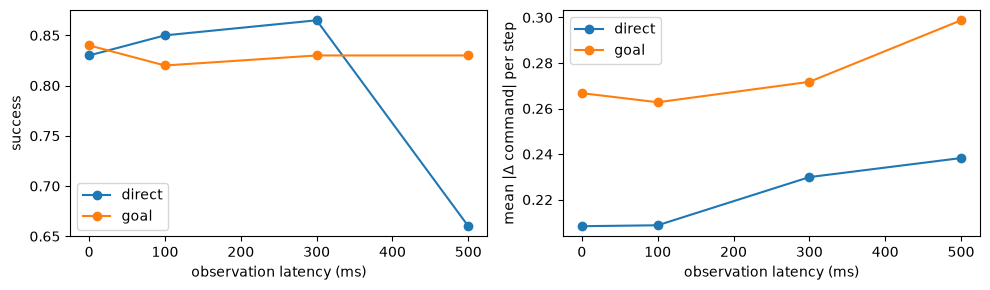

In [3]:
lat_res = {m: [fly(mode=m, latency=L) for L in (0, 1, 3, 5)] for m in ("direct", "goal")}
for m, rs in lat_res.items():
    for L, r in zip((0, 1, 3, 5), rs):
        show(f"{m:6s} latency {L * 100:3d} ms", r)

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for m, rs in lat_res.items():
    axs[0].plot([0, 100, 300, 500], [r["success"].mean() for r in rs], "o-", label=m)
    axs[1].plot([0, 100, 300, 500], [r["jerk"].mean() for r in rs], "o-", label=m)
axs[0].set_ylabel("success"); axs[1].set_ylabel("mean |Δ command| per step")
for a in axs:
    a.set_xlabel("observation latency (ms)"); a.legend()
plt.tight_layout(); plt.show()

Direct control acts on where the drone *was*, so with growing latency it overshoots and oscillates around the
target (book 13.4's dead-time effect, here in a learned policy). The goal-level loop is far less sensitive: a
stale observation still yields a nearly correct *waypoint*, because the waypoint is anchored to the observed
position, and the fast loop uses the current position.

## 3. Keep-out zones and the CBF filter (book 12.4, 13.5)
Every episode now has a keep-out zone across the path to the target. The policy cannot see it (it is in the map,
not the image). First, the filter's parameters, with the direct policy:

In [4]:
show("direct, zones, no filter", fly(mode="direct", zone_prob=1))
for margin, alpha in [(0.0, 5.0), (0.02, 5.0), (0.03, 3.0), (0.04, 3.0)]:
    show(f"direct, zones, CBF margin {margin:.2f} alpha {alpha:.0f}", fly(mode="direct", zone_prob=1, filt=True,
                                                                          margin=margin, alpha=alpha))

direct, zones, no filter                       success 0.83  zone violations 0.81  fence exits 0.00  steps 29.5  |Δcmd| 0.21


direct, zones, CBF margin 0.00 alpha 5         success 0.82  zone violations 0.67  fence exits 0.00  steps 35.2  |Δcmd| 0.25


direct, zones, CBF margin 0.02 alpha 5         success 0.81  zone violations 0.32  fence exits 0.00  steps 37.3  |Δcmd| 0.25


direct, zones, CBF margin 0.03 alpha 3         success 0.81  zone violations 0.01  fence exits 0.00  steps 38.9  |Δcmd| 0.21


direct, zones, CBF margin 0.04 alpha 3         success 0.81  zone violations 0.00  fence exits 0.00  steps 39.6  |Δcmd| 0.20


Without a margin the filter is not enough: it assumes the vehicle's velocity equals the command ($\dot{\mathbf{x}}=\mathbf{u}$),
but this drone's velocity lags the setpoint by 0.25 s and the wind pushes it. A margin that covers the lag
and the gusts, with a gentler $\alpha$, removes the violations at the cost of longer flights — the
model-dependence of book 12.4 measured. Now both architectures with the tuned filter:

direct zones, filtered (0.04, 3)               success 0.81  zone violations 0.00  fence exits 0.00  steps 39.6  |Δcmd| 0.20


goal   zones, filtered (0.04, 3)               success 0.82  zone violations 0.00  fence exits 0.00  steps 38.5  |Δcmd| 0.23


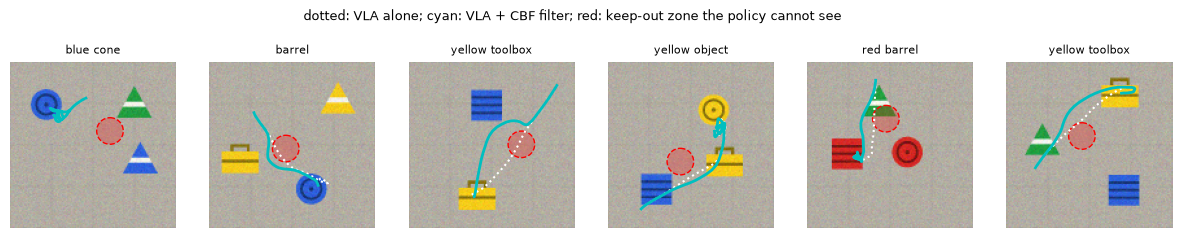

In [5]:
for m in ("direct", "goal"):
    show(f"{m:6s} zones, filtered (0.04, 3)", fly(mode=m, zone_prob=1, filt=True, margin=0.04))

r = fly(n=6, mode="direct", zone_prob=1, filt=True, margin=0.04, trace=True, seed=30_010)
r0 = fly(n=6, mode="direct", zone_prob=1, filt=False, trace=True, seed=30_010)
fig, axs = plt.subplots(1, 6, figsize=(15, 2.8))
for k, ax in enumerate(axs):
    e = r["envs"][k]
    ax.imshow(scenes.render(e.scene, 128), extent=(0, 1, 1, 0))
    for c, rad in e.zones:
        ax.add_patch(plt.Circle(c, rad, fc=(1, 0, 0, 0.25), ec="red", ls="--"))
    p0, p1 = np.array(r0["paths"][k]), np.array(r["paths"][k])
    ax.plot(p0[:, 0], p0[:, 1], "w:", lw=1.5); ax.plot(p1[:, 0], p1[:, 1], "c-", lw=2)
    ax.set_title(e.instruction.replace("go to the ", ""), fontsize=8); ax.axis("off")
plt.suptitle("dotted: VLA alone; cyan: VLA + CBF filter; red: keep-out zone the policy cannot see", fontsize=9)
plt.show()

## 4. Link loss and the watchdog
1.5 s of silence starting 0.6 s into each flight: no VLA decision is delivered. Without a watchdog, the direct
architecture keeps repeating its last velocity command; the goal-level one keeps flying to its last waypoint.

In [6]:
for m in ("direct", "goal"):
    for wd in (False, True):
        rr = fly(mode=m, outage=(6, 15), watchdog=wd, wd_steps=3 if m == "direct" else 10)
        show(f"{m:6s} link loss, watchdog {'on ' if wd else 'off'}", rr)
        print(f"{'':46s} distance flown during the outage: mean {rr['drift'].mean():.2f}, max {rr['drift'].max():.2f}")

direct link loss, watchdog off                 success 0.82  no zones  fence exits 0.32  steps 44.5  |Δcmd| 0.18
                                               distance flown during the outage: mean 0.51, max 0.68


direct link loss, watchdog on                  success 0.83  no zones  fence exits 0.00  steps 42.7  |Δcmd| 0.29
                                               distance flown during the outage: mean 0.13, max 0.21


goal   link loss, watchdog off                 success 0.82  no zones  fence exits 0.00  steps 36.4  |Δcmd| 0.27
                                               distance flown during the outage: mean 0.31, max 0.44


goal   link loss, watchdog on                  success 0.81  no zones  fence exits 0.00  steps 36.2  |Δcmd| 0.24
                                               distance flown during the outage: mean 0.29, max 0.40


**What the numbers say** (check them against your run):

* A stale direct command is dangerous: during the outage the drone keeps flying in the last commanded direction —
  past its target and towards the fence. A watchdog that hovers after 0.3 s bounds the drift to the braking
  distance.
* The goal-level architecture degrades gracefully by construction: without new decisions it reaches the last
  waypoint and stops there. Its watchdog matters less, and can use a longer timeout.
* The safety filter only protects against what it knows (zones and fence in the map) and only as well as its
  model of the vehicle (margins). It does nothing for a wrong target.

## Exercises
1. **Time alignment.** In direct mode with latency $L$, skip the first $L$ actions of each chunk (book 11.3).
   How much of the latency penalty does this recover?
2. **Latency-dependent speed limit.** Scale the commanded speed by $1/(1+4\,\delta)$ as in book 13.5's
   supervisor. Plot success and flight time against latency.
3. **Higher-order CBF.** Write a barrier for the lagged dynamics using the vehicle's velocity
   ($h_2=\dot h+\alpha_1 h$) and compare the margin it needs with the single-integrator filter.
4. **Wrong target.** Corrupt 10% of instructions (swap the colour word). Which layer catches the error? What
   would? (Book 11.5.)
5. **Deadlock.** Put the zone exactly on the line to the target (no offset). What happens with the filter,
   and how would a planner fix it?